In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
from pathlib import Path

In [4]:
DATA_PATH = Path(
    r"E:\internhips\infotact solutions\TerraSpectra Hyperspectral Crop Disease Forecasting\backend\data\TerraSpectra_Synthetic_Demo_Dataset\synthetic_hsi_demo.npz"
)

data = np.load(DATA_PATH)

cube = data["cube"]
labels = data["labels"]
wavelengths = data["wavelengths_nm"]

In [6]:
print("Hyperspectral cube shape:", cube.shape)
print("Labels shape:", labels.shape)
print("Number of spectral bands:", len(wavelengths))

print("Unique labels:", np.unique(labels))

Hyperspectral cube shape: (32, 32, 16)
Labels shape: (32, 32)
Number of spectral bands: 16
Unique labels: [0 1]


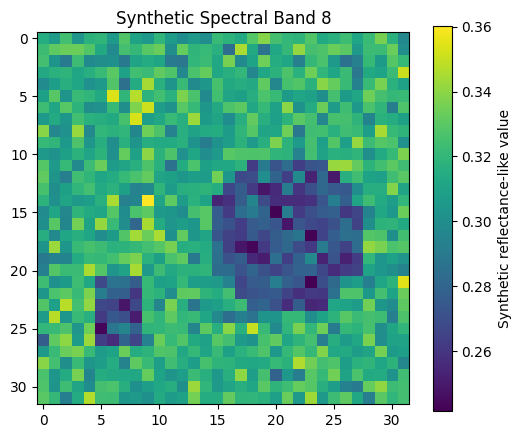

In [7]:
plt.figure(figsize=(6, 5))

plt.imshow(cube[:, :, 7], cmap="viridis")
plt.title("Synthetic Spectral Band 8")
plt.colorbar(label="Synthetic reflectance-like value")

plt.show()

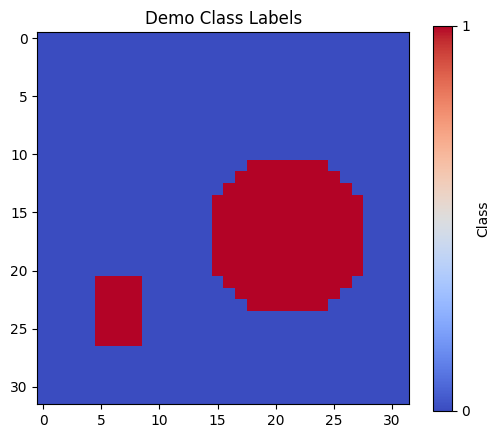

In [8]:
plt.figure(figsize=(6, 5))

plt.imshow(labels, cmap="coolwarm", vmin=0, vmax=1)
plt.title("Demo Class Labels")
plt.colorbar(ticks=[0, 1], label="Class")

plt.show()

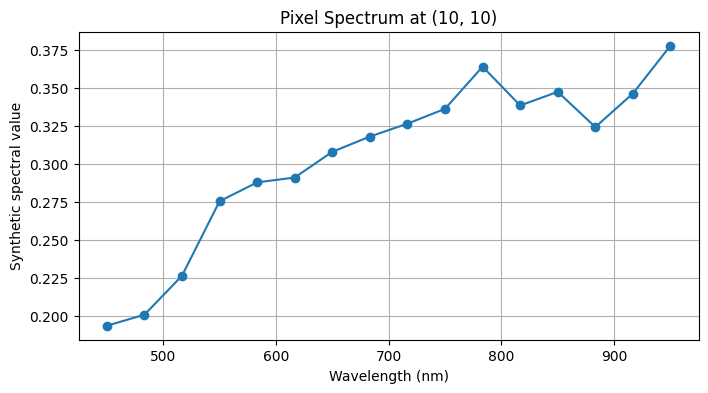

In [9]:
row = 10
col = 10

spectrum = cube[row, col, :]

plt.figure(figsize=(8, 4))

plt.plot(wavelengths, spectrum, marker="o")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Synthetic spectral value")
plt.title(f"Pixel Spectrum at ({row}, {col})")
plt.grid(True)

plt.show()

In [10]:
csv_path = DATA_PATH.parent / "pixel_spectra.csv"

df = pd.read_csv(csv_path)

df.head()

,row,col,label,class_name,band_01,band_02,band_03,band_04,band_05,band_06,band_07,band_08,band_09,band_10,band_11,band_12,band_13,band_14,band_15,band_16
0,0,0,0,healthy_demo,0.185869,0.196336,0.243337,0.269057,0.254921,0.279858,0.310529,0.315177,0.325640,0.320079,0.343874,0.345257,0.340012,0.357773,0.357493,0.352457
1,0,1,0,healthy_demo,0.163611,0.212262,0.226637,0.248457,0.263067,0.303059,0.300045,0.306736,0.314521,0.329608,0.330612,0.333781,0.337294,0.362851,0.339910,0.349527
2,0,2,0,healthy_demo,0.189126,0.221886,0.232486,0.247211,0.267962,0.302813,0.317436,0.325011,0.317378,0.332623,0.334244,0.338070,0.349199,0.346452,0.359552,0.363102
3,0,3,0,healthy_demo,0.184801,0.186343,0.225509,0.247139,0.265681,0.287196,0.321947,0.303595,0.332474,0.305134,0.324316,0.332890,0.341267,0.347794,0.356416,0.353597
4,0,4,0,healthy_demo,0.183121,0.197133,0.209635,0.234783,0.257913,0.292062,0.301316,0.317870,0.311327,0.322830,0.331441,0.322823,0.335313,0.326916,0.338138,0.348800


In [ ]:
# avalabality 
print(df.columns)
print(df.shape)

Index(['row', 'col', 'label', 'class_name', 'band_01', 'band_02', 'band_03',
       'band_04', 'band_05', 'band_06', 'band_07', 'band_08', 'band_09',
       'band_10', 'band_11', 'band_12', 'band_13', 'band_14', 'band_15',
       'band_16'],
      dtype='object')
(1024, 20)


In [13]:
print("Cube shape:", cube.shape)
print("Labels shape:", labels.shape)

assert cube.shape == (32, 32, 16)
assert labels.shape == (32, 32)

print("Unique labels:", np.unique(labels))

Cube shape: (32, 32, 16)
Labels shape: (32, 32)
Unique labels: [0 1]


In [14]:
unique, counts = np.unique(labels, return_counts=True)

for label, count in zip(unique, counts):
    print(f"Class {label}: {count} pixels")

Class 0: 855 pixels
Class 1: 169 pixels


In [15]:
X = cube.reshape(-1, 16)
y = labels.reshape(-1)

print("X:", X.shape)
print("y:", y.shape)

X: (1024, 16)
y: (1024,)


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(819, 16)
(205, 16)


# Traning RF Classsifiere

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print(classification_report(y_test, rf_predictions))
print(confusion_matrix(y_test, rf_predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       171
           1       1.00      1.00      1.00        34

    accuracy                           1.00       205
   macro avg       1.00      1.00      1.00       205
weighted avg       1.00      1.00      1.00       205

[[171   0]
 [  0  34]]


In [20]:
import joblib

joblib.dump(
    rf_model,
    r"E:\internhips\infotact solutions\TerraSpectra Hyperspectral Crop Disease Forecasting\backend\artifacts\random_forest_baseline.joblibartifacts"
)

['E:\\internhips\\infotact solutions\\TerraSpectra Hyperspectral Crop Disease Forecasting\\backend\\artifacts\\random_forest_baseline.joblibartifacts']

In [21]:

import torch
from torch.utils.data import Dataset

class HyperspectralDataset(Dataset):

    def __init__(self, cube, labels, patch_size=3):
        self.cube = torch.tensor(
            cube, dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels, dtype=torch.long
        )

        self.patch_size = patch_size
        self.pad = patch_size // 2

        self.cube = torch.nn.functional.pad(
            self.cube.permute(2, 0, 1).unsqueeze(0),
            (self.pad, self.pad, self.pad, self.pad),
            mode="reflect"
        ).squeeze(0).permute(1, 2, 0)

    def __len__(self):
        return self.labels.shape[0] * self.labels.shape[1]

    def __getitem__(self, idx):

        height, width = self.labels.shape

        row = idx // width
        col = idx % width

        patch = self.cube[
            row:row + self.patch_size,
            col:col + self.patch_size,
            :
        ]

        patch = patch.permute(2, 0, 1)

        patch = patch.unsqueeze(0)

        label = self.labels[row, col]

        return patch, label


# Data loaders

In [22]:
from torch.utils.data import DataLoader, Subset
import numpy as np

dataset = HyperspectralDataset(cube, labels)

indices = np.arange(len(dataset))

train_indices, test_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=labels.reshape(-1)
)

train_dataset = Subset(dataset, train_indices)
test_dataset = Subset(dataset, test_indices)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

In [23]:
patches, targets = next(iter(train_loader))

print("Batch:", patches.shape)
print("Labels:", targets.shape)

Batch: torch.Size([16, 1, 16, 3, 3])
Labels: torch.Size([16])
